In [1]:
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from matplotlib.colors import to_rgb, to_hex
from matplotlib.patches import Ellipse
from nibabel.freesurfer import read_annot
from nilearn import plotting
from scipy.stats import chi2, zscore

ROOT = Path.cwd()
if ROOT.name == 'figure_code':
    ROOT = ROOT.parent

DATA_DIR = ROOT / 'data'

BASE_DIR = DATA_DIR
MAP_DIR = BASE_DIR / 'maps/fsaverage5'

LH_MESH = MAP_DIR / 'surf/lh.inflated'
RH_MESH = MAP_DIR / 'surf/rh.inflated'
LH_ANNOT = MAP_DIR / 'roi/lh.Schaefer2018_300Parcels_17Networks_order.annot'
RH_ANNOT = MAP_DIR / 'roi/rh.Schaefer2018_300Parcels_17Networks_order.annot'

FEATURE_ORDER = ['lv', 'mv', 'hv', 'sm']
FEATURE_LABELS = {'lv': 'low-visual feature', 'mv': 'mid-visual feature', 'hv': 'high-visual feature', 'sm': 'semantic feature'}

NETWORK_ORDER = ['Vis', 'SomMot', 'DorsAttn', 'SalVentAttn', 'Limbic', 'Cont', 'Default', 'TempPar']

NETWORK_COLORS = {
    'Vis': '#C45161',
    'SomMot': '#E094A0',
    'DorsAttn': '#F2B6C0',
    'SalVentAttn': '#F2DDE1',
    'Limbic': '#CBC7D8',
    'Cont': '#8DB7D2',
    'TempPar': '#434279',
    'Default': '#7378DA',
}

with open(BASE_DIR / 'encode_summary_pooled.pkl', 'rb') as f:
    encoding_results = pickle.load(f)

with open(BASE_DIR / 'recall_summary_pooled.pkl', 'rb') as f:
    recall_results = pickle.load(f)

atlas_labels = pd.read_csv(
    BASE_DIR / 'maps/Schaefer2018_300Parcels_17Networks_order.txt',
    sep=r'\s+', header=None, usecols=[0, 1], names=['roi', 'label'],
)
atlas_labels['network'] = (
    atlas_labels['label'].str.extract(r'_(?:LH|RH)_([^_]+)', expand=False)
    .str.replace(r'[ABC]$', '', regex=True)
    .replace({'VisCent': 'Vis', 'VisPeri': 'Vis'})
)

plot_data = pd.concat([
    encoding_results[feature][['roi', 'median_accuracy']]
    .rename(columns={'median_accuracy': 'encoding'})
    .merge(
        recall_results[feature][['roi', 'median_accuracy']]
        .rename(columns={'median_accuracy': 'recall'}),
        on='roi', validate='one_to_one',
    )
    .assign(feature=feature)
    for feature in FEATURE_ORDER
], ignore_index=True).merge(
    atlas_labels[['roi', 'network']], on='roi', validate='many_to_one',
)

In [4]:
def annot_to_vertex_values(annot_file, roi_values):
    labels_vertex, _, names = read_annot(str(annot_file))
    roi_values = np.asarray(roi_values, dtype=float)

    parcel_ids = np.arange(1, len(names))
    vertex_data = np.full(labels_vertex.shape, np.nan, dtype=float)

    for parcel_id, value in zip(parcel_ids, roi_values):
        vertex_data[labels_vertex == parcel_id] = value

    return vertex_data, labels_vertex


def plot_schaefer_surface(vec, cmap, vmin, vmax, title='', cbar_label=None, figsize=(10, 8)):
    vec = np.asarray(vec, dtype=float)
    lh_data, lh_labels = annot_to_vertex_values(LH_ANNOT, vec[:150])
    rh_data, rh_labels = annot_to_vertex_values(RH_ANNOT, vec[150:])

    fig, axes = plt.subplots(2, 2, figsize=figsize, subplot_kw={'projection': '3d'})

    views = [
        ('left', 'lateral', LH_MESH, lh_data, lh_labels, axes[0, 0]),
        ('right', 'lateral', RH_MESH, rh_data, rh_labels, axes[0, 1]),
        ('left', 'medial', LH_MESH, lh_data, lh_labels, axes[1, 0]),
        ('right', 'medial', RH_MESH, rh_data, rh_labels, axes[1, 1]),
    ]

    for hemi, view, mesh, data, parcel_labels, ax in views:
        plotting.plot_surf_stat_map(surf_mesh=str(mesh), stat_map=data, hemi=hemi, view=view, bg_map=np.ones(len(data)) * 0.5,
                                    cmap=cmap, colorbar=False, threshold=None, vmin=vmin, vmax=vmax, axes=ax)

        levels = sorted(np.unique(parcel_labels[parcel_labels > 0]))
        plotting.plot_surf_contours(surf_mesh=str(mesh), roi_map=parcel_labels, hemi=hemi, view=view, levels=levels,
                                    colors=['#545252'] * len(levels), legend=False, axes=ax)

    fig.suptitle(title, y=0.98)

    sm = cm.ScalarMappable(norm=colors.Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
    sm.set_array([])
    cax = fig.add_axes([0.35, 0.46, 0.30, 0.03])
    cbar = fig.colorbar(sm, cax=cax, orientation='horizontal')
    cbar.set_label(cbar_label)

    plt.tight_layout()
    return fig, axes


def feature_to_vec(df, q_thresh=0.05):
    q = df['q_value'].astype(float).to_numpy()
    keep = np.isfinite(q) & (q < q_thresh)

    vec = np.full(300, np.nan)
    roi = df.loc[keep, 'roi'].astype(int).to_numpy() - 1
    vec[roi] = df.loc[keep, 'accuracy'].to_numpy()

    return vec

/var/folders/x7/6t7hmgfs28j4rk_w_qvw28fh0000gn/T/ipykernel_82232/3511808919.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/var/folders/x7/6t7hmgfs28j4rk_w_qvw28fh0000gn/T/ipykernel_82232/3511808919.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/var/folders/x7/6t7hmgfs28j4rk_w_qvw28fh0000gn/T/ipykernel_82232/3511808919.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/var/folders/x7/6t7hmgfs28j4rk_w_qvw28fh0000gn/T/ipykernel_82232/3511808919.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/var/folders/x7/6t7hmgfs28j4rk_w_qvw28fh0000gn/T/ipykernel_82232/3511808919.py:44: UserWarning: This figure includes Axes that are n

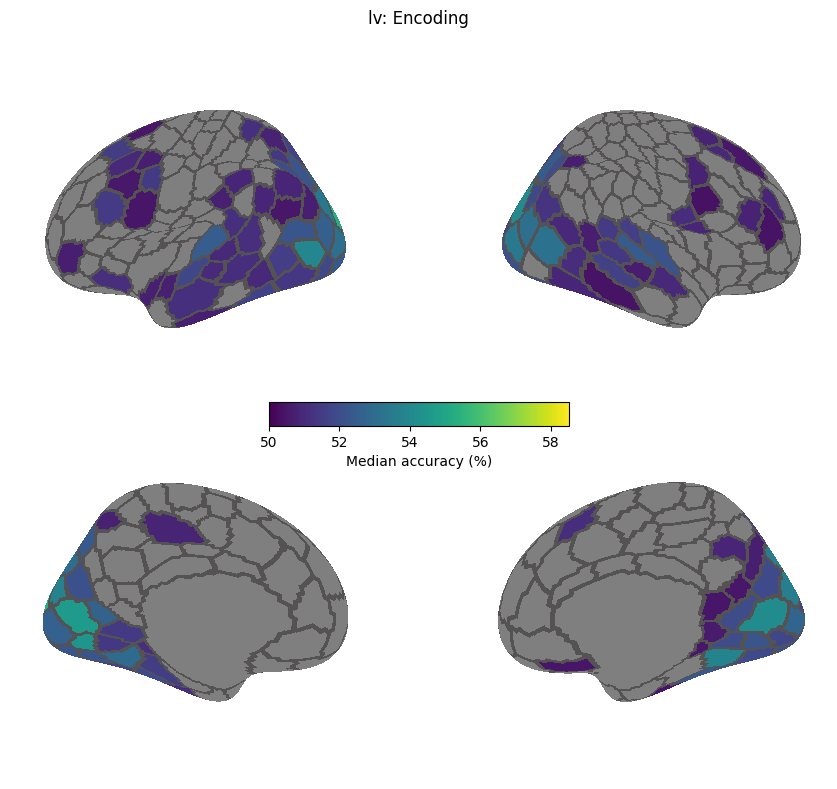

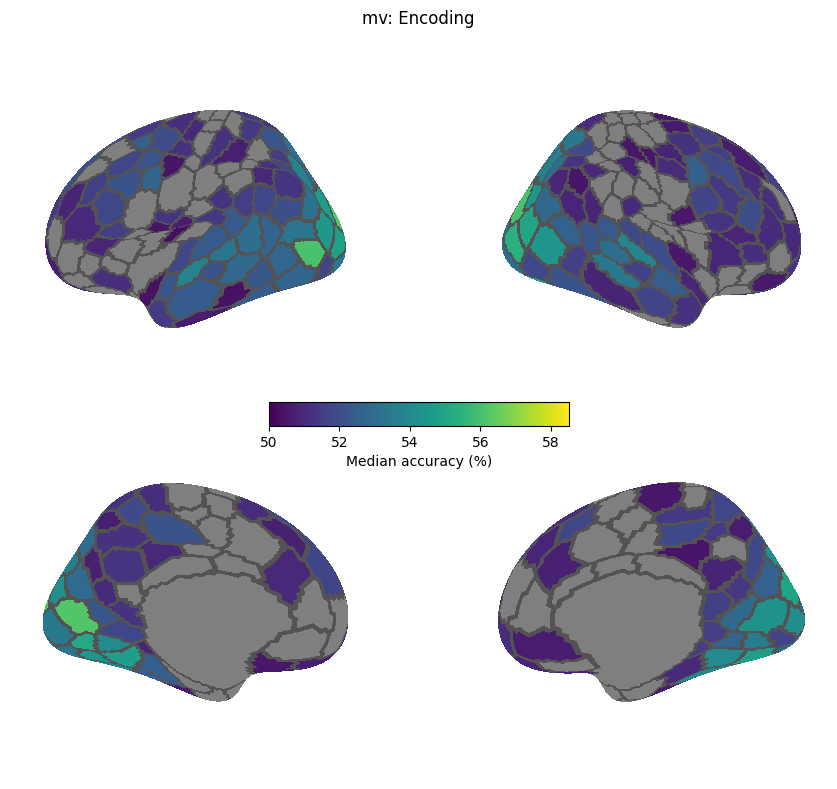

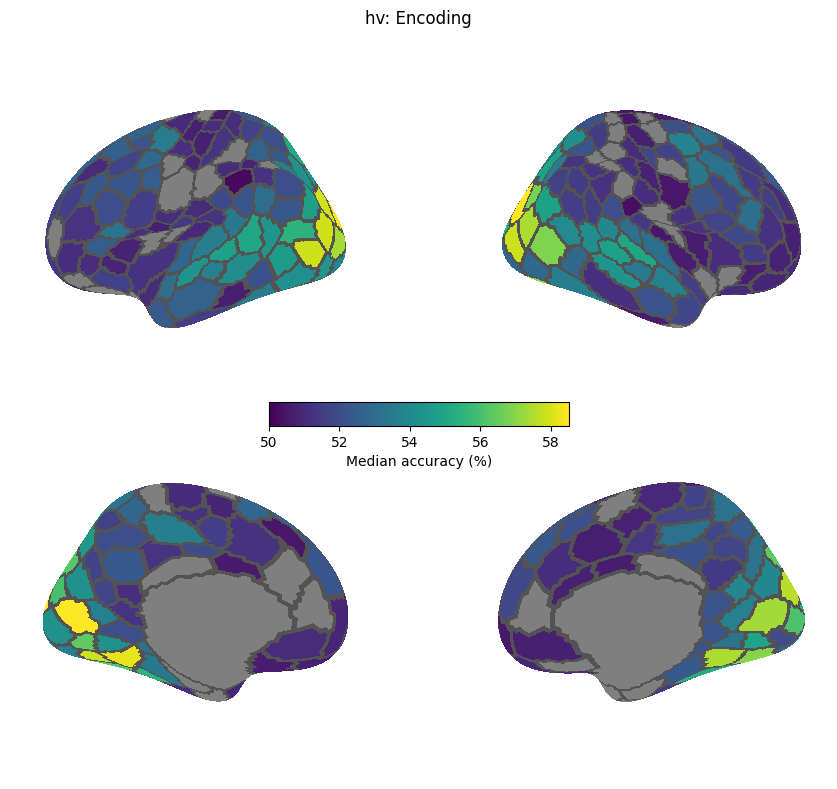

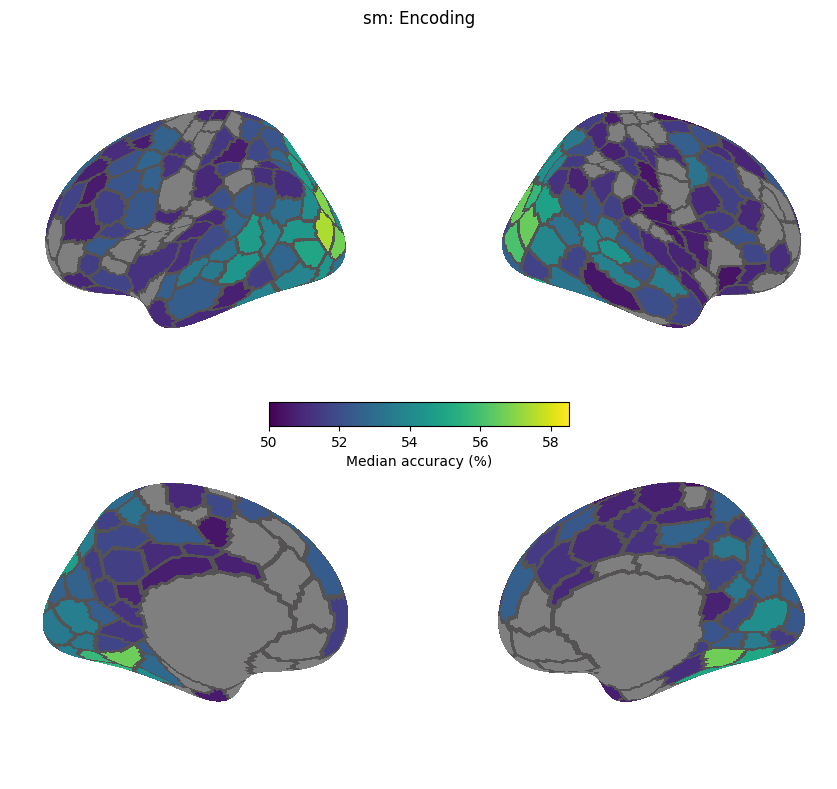

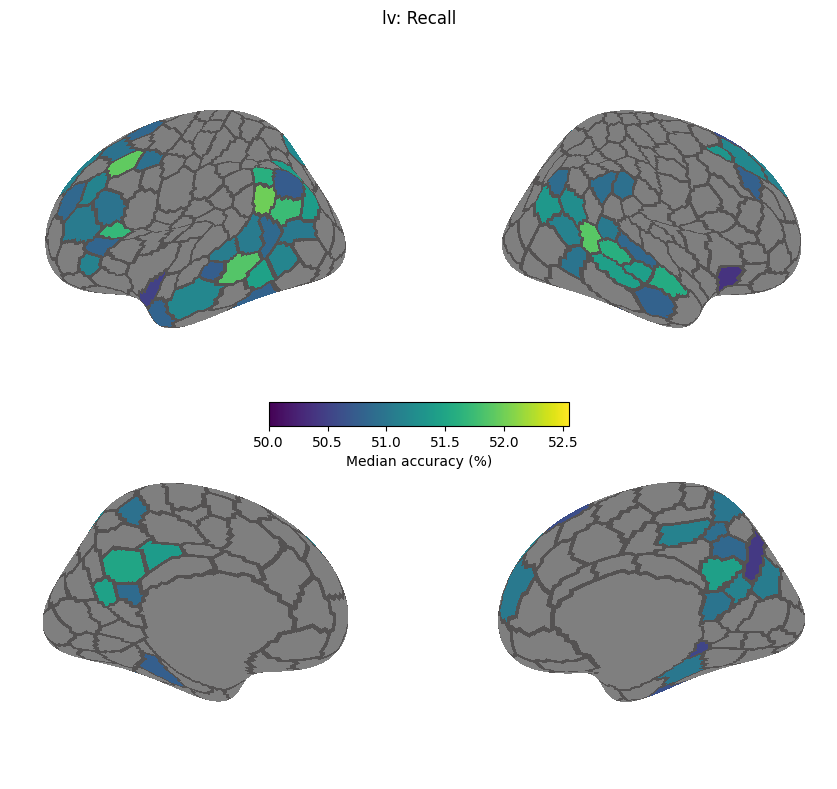

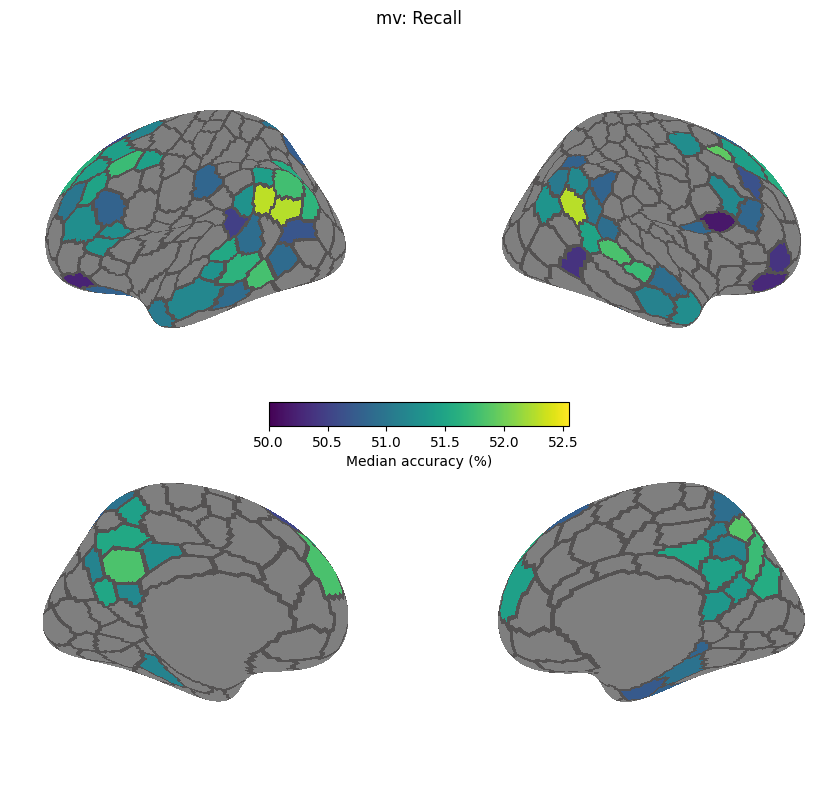

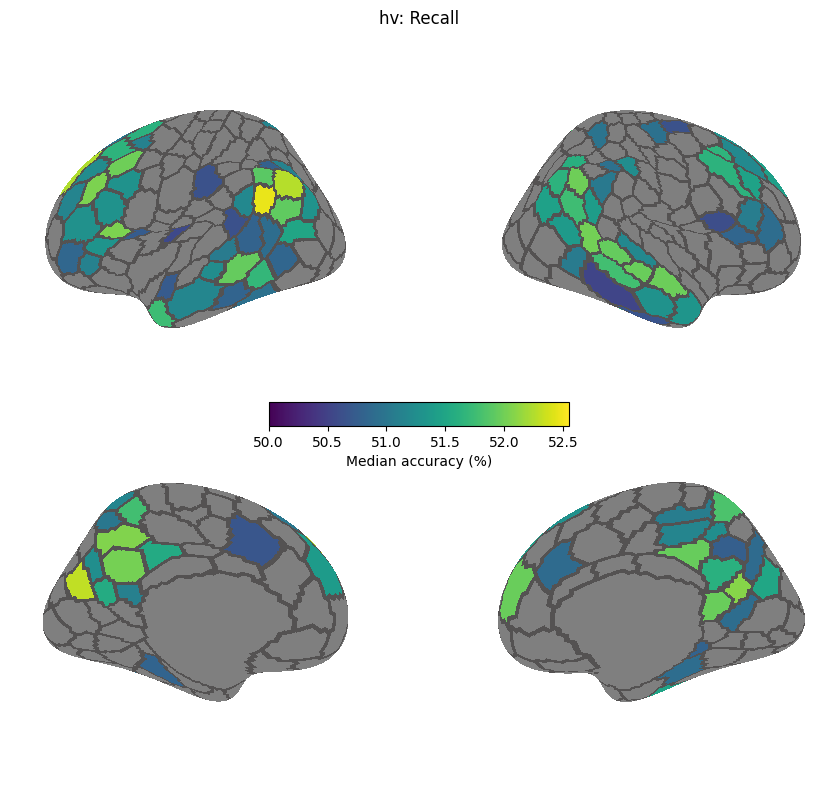

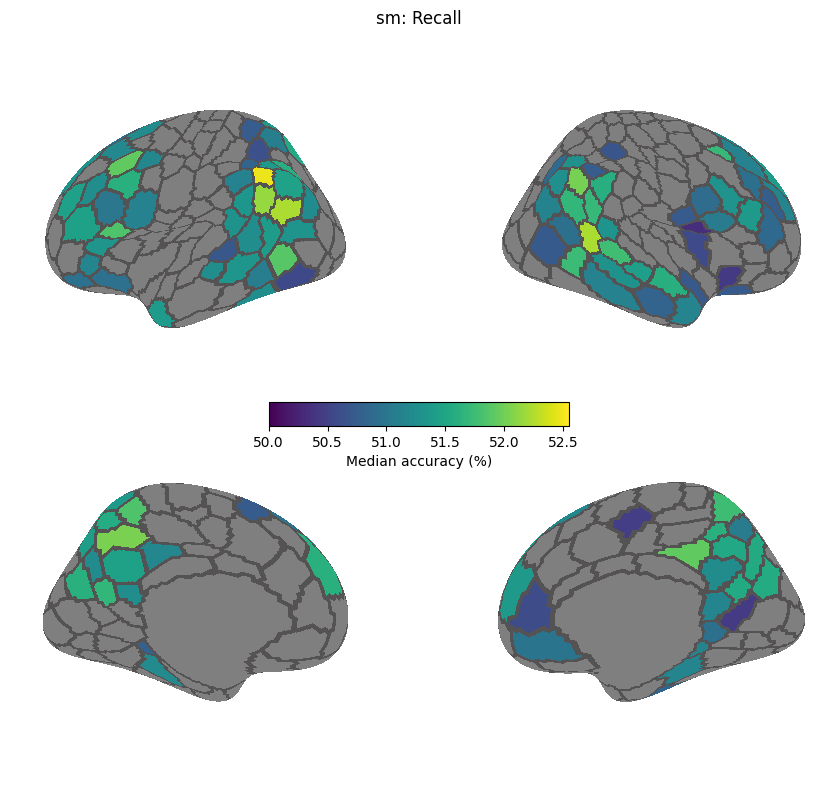

In [5]:
surface_configs = {
    'Encoding': (encoding_results, 50, 58.5),
    'Recall': (recall_results, 50, 52.55),
}

for state, (state_results, vmin, vmax) in surface_configs.items():
    for feature in FEATURE_ORDER:
        plot_df = state_results[feature].copy()
        plot_df['accuracy'] = plot_df['median_accuracy'] * 100
        vec = feature_to_vec(plot_df)

        plot_schaefer_surface(vec, cmap='viridis', vmin=vmin, vmax=vmax,
                              title=f'{feature}: {state}', cbar_label='Median accuracy (%)')

In [6]:
def _ink(color, thresh=0.72, factor=0.72, always=False):
    r, g, b = to_rgb(color)
    if always or 0.299 * r + 0.587 * g + 0.114 * b > thresh:
        return to_hex((r * factor, g * factor, b * factor))
    return to_hex((r, g, b))


def _ellipse_geom(x, y, level=0.95, min_parcels=4):
    xy = np.column_stack([np.asarray(x, float), np.asarray(y, float)])
    xy = xy[~np.isnan(xy).any(axis=1)]
    cx, cy = xy.mean(0)

    vals, vecs = np.linalg.eigh(np.cov(xy.T))
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    width, height = 2 * np.sqrt(np.maximum(vals, 0) * chi2.ppf(level, df=2))
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    return (cx, cy), (width, height, angle)

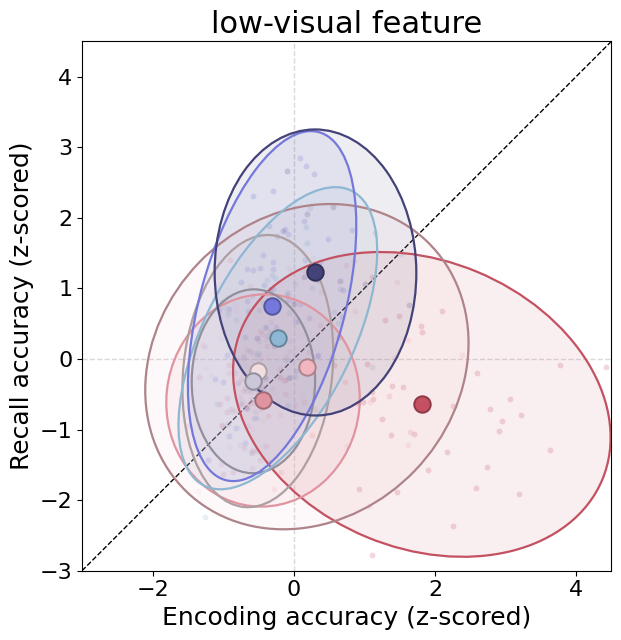

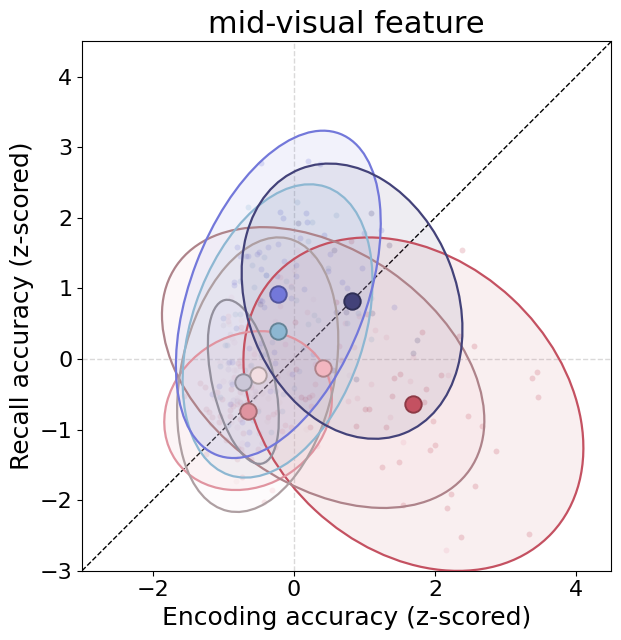

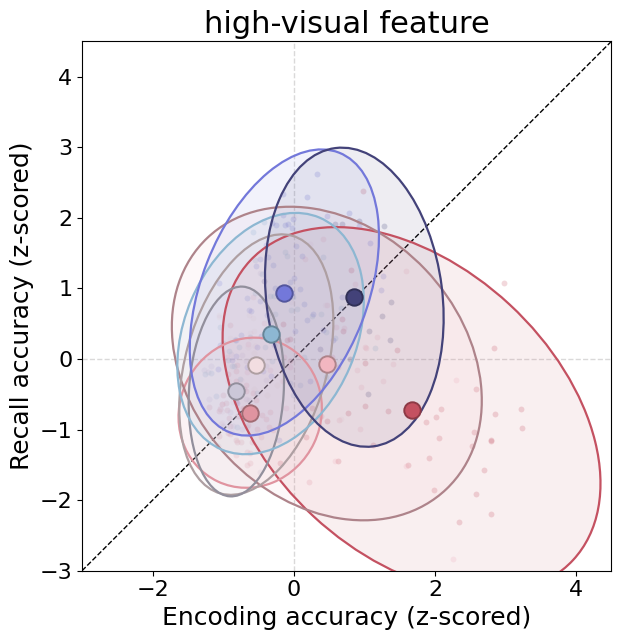

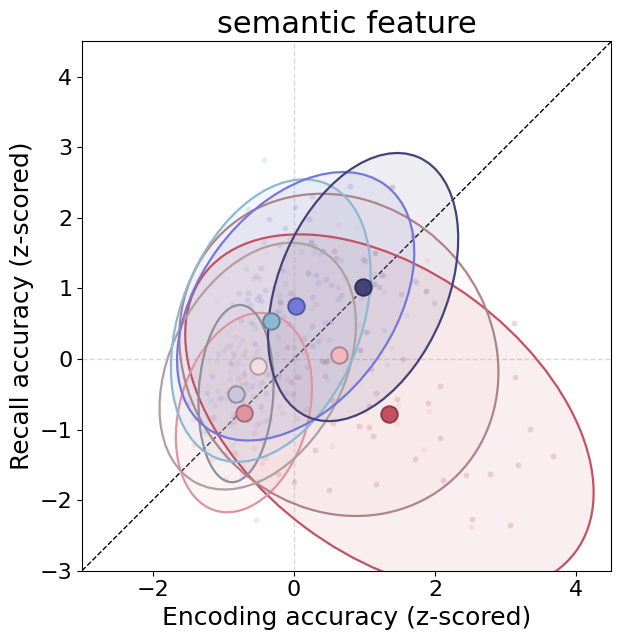

In [10]:
for feature in FEATURE_ORDER:
    df = plot_data.loc[plot_data['feature'].eq(feature)]
    roi_mean = df[['roi', 'network', 'encoding', 'recall']].copy()

    roi_mean['encoding_z'] = zscore(roi_mean['encoding'], nan_policy='omit')
    roi_mean['recall_z'] = zscore(roi_mean['recall'], nan_policy='omit')

    fig, ax = plt.subplots(figsize=(7, 6.5))

    for network in NETWORK_ORDER:
        net_df = roi_mean.loc[roi_mean['network'].eq(network)]

        color = NETWORK_COLORS[network]
        edge = _ink(color)
        centroid_edge = _ink(color, always=True)

        x = net_df['encoding_z']
        y = net_df['recall_z']

        ax.scatter(x, y, s=18, alpha=0.22, color=color, linewidths=0, zorder=2)

        (cx, cy), geom = _ellipse_geom(x, y)
        width, height, angle = geom
        ax.add_patch(Ellipse((cx, cy), width, height, angle=angle, facecolor=color, alpha=0.09, edgecolor='none', zorder=3))
        ax.add_patch(Ellipse((cx, cy), width, height, angle=angle, facecolor='none', edgecolor=edge, lw=1.6, zorder=4))

        ax.scatter(cx, cy, s=140, color=color, edgecolor=centroid_edge, linewidth=1.4, zorder=6)

    ax.plot([-3, 4.5], [-3, 4.5], '--', color='black', lw=1, zorder=0)
    ax.axvline(0, color='#8584844D', ls='--', lw=1, zorder=0)
    ax.axhline(0, color='#8584844D', ls='--', lw=1, zorder=0)

    ax.set_xlim(-3, 4.5)
    ax.set_ylim(-3, 4.5)
    ax.set_aspect('equal')
    ax.set_xlabel('Encoding accuracy (z-scored)', fontsize=18)
    ax.set_ylabel('Recall accuracy (z-scored)', fontsize=18)
    ax.set_title(FEATURE_LABELS[feature], fontsize=22)
    ax.tick_params(labelsize=16)

    fig.tight_layout()
    plt.show()